In [1]:
from collections import Counter

from hashlib import sha256

from itertools import chain

from pathlib import Path

from tempfile import TemporaryDirectory

from zipfile import ZipFile
 
import matplotlib.pyplot as plt

import numpy as np

# The source dataset includes iPhone HEIC images.
try:
    from pillow_heif import register_heif_opener
except ModuleNotFoundError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", "--retries", "1", "pillow-heif"])
    from pillow_heif import register_heif_opener

from PIL import Image, ImageOps
register_heif_opener()

from sklearn.metrics import classification_report, ConfusionMatrixDisplay

from sklearn.model_selection import train_test_split

import torch

from torch import nn

from torch.utils.data import DataLoader, Subset

from torchvision import datasets, transforms
 
SEED = 42

IMAGE_SIZE = 128

BATCH_SIZE = 32

EPOCHS = 10

LEARNING_RATE = 0.001
 
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
 
input_dir = Path("/kaggle/input")

expected_classes = {

    "glass", "leather", "organic",

    "paper", "plastic",

}
 
def waste_folders(folder):

    return sorted(

        child.name for child in folder.iterdir()

        if child.is_dir() and child.name.strip().casefold().removesuffix(" waste") in expected_classes

    )
 
def find_dataset_roots(parent):

    return [

        folder for folder in chain([parent], parent.rglob("*"))

        if folder.is_dir()

        and {name.strip().casefold().removesuffix(" waste") for name in waste_folders(folder)} == expected_classes

    ]
 
roots = find_dataset_roots(input_dir)
 
if not roots:

    archives = sorted(input_dir.rglob("*.zip"))

    if len(archives) != 1:

        raise RuntimeError(

            "Attach the waste dataset using Add Input. "

            f"Expected one ZIP or extracted class folders. Found ZIPs: {archives}"

        )
 
    extracted = TemporaryDirectory(prefix="waste_images_")

    with ZipFile(archives[0]) as archive:

        archive.extractall(extracted.name)

    roots = find_dataset_roots(Path(extracted.name))
 
if len(roots) != 1:

    raise RuntimeError(

        f"Expected one folder containing all five waste classes. Found: {roots}"

    )
 
data_root = roots[0]
 
class WasteImageFolder(datasets.ImageFolder):

    def find_classes(self, directory):

        classes = waste_folders(Path(directory))

        if len(classes) != len(expected_classes):

            raise ValueError(f"Expected five class folders. Found: {classes}")

        return classes, {name: index for index, name in enumerate(classes)}
 
base_dataset = WasteImageFolder(
    data_root, is_valid_file=lambda name: Path(name).suffix.lower() in Image.registered_extensions()
)
cache = TemporaryDirectory(prefix="waste_rgb_")
cache_root = Path(cache.name)
for name in base_dataset.classes:
    (cache_root / name).mkdir()

class_names = base_dataset.classes
 
# Exclude unreadable images and exact duplicates before splitting.

seen = {}

usable_indices = []

unreadable = duplicates = 0
 
for index, (filename, label) in enumerate(base_dataset.samples):

    path = Path(filename)

    try:

        with Image.open(path) as image:

            prepared_image = ImageOps.exif_transpose(image).convert("RGB").resize(
                (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR
            )

        digest = sha256(path.read_bytes()).digest()

    except (OSError, ValueError):

        unreadable += 1

        continue
 
    if digest in seen:

        previous_label, previous_path = seen[digest]

        if previous_label != label:

            raise ValueError(f"Conflicting labels for identical files: {previous_path}, {path}")

        duplicates += 1

        continue
 
    seen[digest] = (label, path)

    prepared_image.save(cache_root / class_names[label] / f"{index:06d}.png")
    usable_indices.append(index)
    if len(usable_indices) % 200 == 0:
        print(f"Prepared {len(usable_indices)} images", flush=True)
 
original_count = len(base_dataset)
print("Dataset folder:", data_root)

print("Classes:", class_names)

print(f"Usable images: {len(usable_indices)} of {original_count}")

print(f"Unreadable: {unreadable} | Exact duplicates: {duplicates}")
 

# Train from cached RGB images so each source file is decoded only once.
data_root = cache_root
base_dataset = WasteImageFolder(data_root)
usable_indices = list(range(len(base_dataset)))


Device: cuda
Prepared 200 images
Prepared 400 images
Prepared 600 images
Prepared 800 images
Prepared 1000 images
Prepared 1200 images
Prepared 1400 images
Prepared 1600 images
Prepared 1800 images
Dataset folder: /kaggle/input/datasets/jannatulmeem1108/mendeley-waste-classification/Automatic waste management dataset/Automatic waste management dataset
Classes: ['Glass', 'Leather', 'Organic', 'Paper', 'Plastic']
Usable images: 1967 of 1973
Unreadable: 0 | Exact duplicates: 6


Train: 1376 images | {'Leather': 201, 'Paper': 317, 'Glass': 289, 'Organic': 282, 'Plastic': 287}
Validation: 295 images | {'Plastic': 61, 'Paper': 68, 'Organic': 61, 'Glass': 62, 'Leather': 43}
Test: 296 images | {'Leather': 43, 'Paper': 68, 'Glass': 62, 'Plastic': 62, 'Organic': 61}


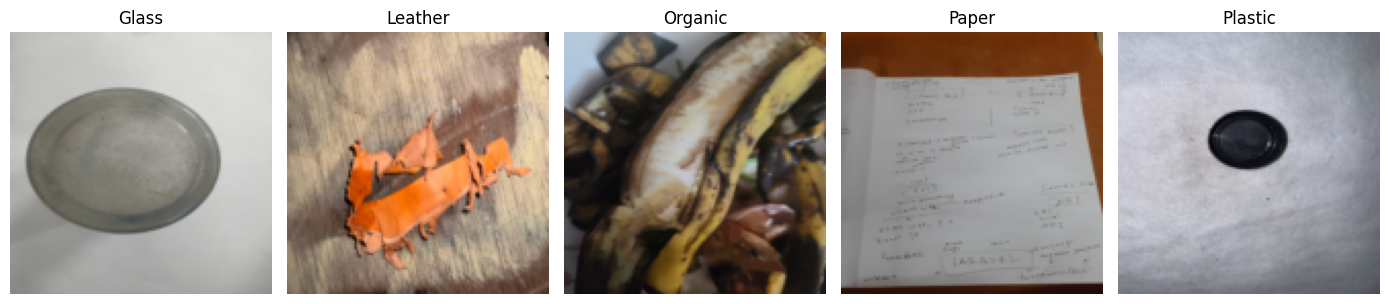

In [2]:
labels = np.asarray(base_dataset.targets)
 
train_idx, holdout_idx = train_test_split(

    usable_indices, test_size=0.30,

    random_state=SEED, stratify=labels[usable_indices],

)

val_idx, test_idx = train_test_split(

    holdout_idx, test_size=0.50,

    random_state=SEED, stratify=labels[holdout_idx],

)
 
for split, indices in [

    ("Train", train_idx), ("Validation", val_idx), ("Test", test_idx)

]:

    counts = Counter(class_names[labels[i]] for i in indices)

    print(f"{split}: {len(indices)} images | {dict(counts)}")
 
train_transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.RandomHorizontalFlip(),

    transforms.ToTensor(),

])
 
eval_transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

])
 
train_dataset = WasteImageFolder(data_root, transform=train_transform)

base_dataset.transform = eval_transform
 
train_loader = DataLoader(

    Subset(train_dataset, train_idx), batch_size=BATCH_SIZE, shuffle=True

)

val_loader = DataLoader(Subset(base_dataset, val_idx), batch_size=BATCH_SIZE)

test_loader = DataLoader(Subset(base_dataset, test_idx), batch_size=BATCH_SIZE)
 
fig, axes = plt.subplots(1, len(class_names), figsize=(14, 3))

for class_id, ax in enumerate(axes):

    index = next(i for i in train_idx if labels[i] == class_id)

    image, _ = base_dataset[index]

    ax.imshow(image.permute(1, 2, 0))

    ax.set_title(class_names[class_id])

    ax.axis("off")
 
plt.tight_layout()

plt.show()
 

In [3]:
from math import isfinite


def conv_block(in_channels, out_channels):
    return [
        nn.Conv2d(in_channels, out_channels, 3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(2),
    ]


model = nn.Sequential(
    *conv_block(3, 32),
    *conv_block(32, 64),
    *conv_block(64, 128),
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Dropout(0.25),
    nn.Linear(128, len(class_names)),
).to(device)

model.eval()
with torch.inference_mode():
    x = torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    for layer in model:
        x = layer(x)
        print(f"{type(layer).__name__:<22} {str(tuple(x.shape)):<24} {sum(p.numel() for p in layer.parameters()):,}")
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
weights_path = Path("/kaggle/working/waste_cnn.pth")


def run_epoch(loader, training=False, collect_predictions=False):
    model.train(training)
    loss_sum, correct, total = 0.0, 0, 0
    actual, predicted = [], []
    with torch.set_grad_enabled(training):
        for images, targets in loader:
            images, targets = images.to(device), targets.to(device)
            if training:
                optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, targets)
            if training:
                loss.backward()
                optimizer.step()
            predictions = logits.argmax(dim=1)
            loss_sum += loss.item() * targets.size(0)
            correct += (predictions == targets).sum().item()
            total += targets.size(0)
            if collect_predictions:
                actual.extend(targets.cpu().tolist())
                predicted.extend(predictions.cpu().tolist())
    return loss_sum / total, correct / total, actual, predicted


history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = float("inf")
best_epoch = 0
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, _, _ = run_epoch(train_loader, training=True)
    val_loss, val_acc, _, _ = run_epoch(val_loader)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    if isfinite(val_loss) and val_loss < best_val_loss:
        best_val_loss, best_epoch = val_loss, epoch
        torch.save(model.state_dict(), weights_path)
    print(f"Epoch {epoch:02d}/{EPOCHS} | Train loss {train_loss:.4f}, accuracy {train_acc:.1%} | "
          f"Val loss {val_loss:.4f}, accuracy {val_acc:.1%}", flush=True)

if best_epoch == 0:
    raise RuntimeError("No checkpoint was saved. Check the training and validation losses.")
print("Best validation epoch:", best_epoch)
print("Saved weights:", weights_path)


Conv2d                 (1, 32, 128, 128)        896
BatchNorm2d            (1, 32, 128, 128)        64
ReLU                   (1, 32, 128, 128)        0
MaxPool2d              (1, 32, 64, 64)          0
Conv2d                 (1, 64, 64, 64)          18,496
BatchNorm2d            (1, 64, 64, 64)          128
ReLU                   (1, 64, 64, 64)          0
MaxPool2d              (1, 64, 32, 32)          0
Conv2d                 (1, 128, 32, 32)         73,856
BatchNorm2d            (1, 128, 32, 32)         256
ReLU                   (1, 128, 32, 32)         0
MaxPool2d              (1, 128, 16, 16)         0
AdaptiveAvgPool2d      (1, 128, 1, 1)           0
Flatten                (1, 128)                 0
Dropout                (1, 128)                 0
Linear                 (1, 5)                   645
Trainable parameters: 94341
Epoch 01/10 | Train loss 0.7162, accuracy 80.9% | Val loss 0.8510, accuracy 59.7%
Epoch 02/10 | Train loss 0.3226, accuracy 94.1% | Val loss 0.5843, accu

Test loss: 0.2406
Test accuracy: 93.92%
              precision    recall  f1-score   support

       Glass     0.8732    1.0000    0.9323        62
     Leather     1.0000    0.9302    0.9639        43
     Organic     0.9091    0.9836    0.9449        61
       Paper     0.9492    0.8235    0.8819        68
     Plastic     1.0000    0.9677    0.9836        62

    accuracy                         0.9392       296
   macro avg     0.9463    0.9410    0.9413       296
weighted avg     0.9430    0.9392    0.9386       296



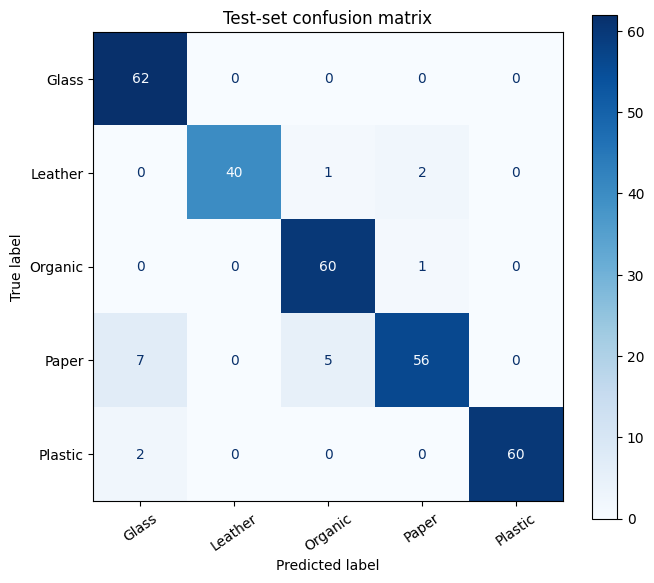

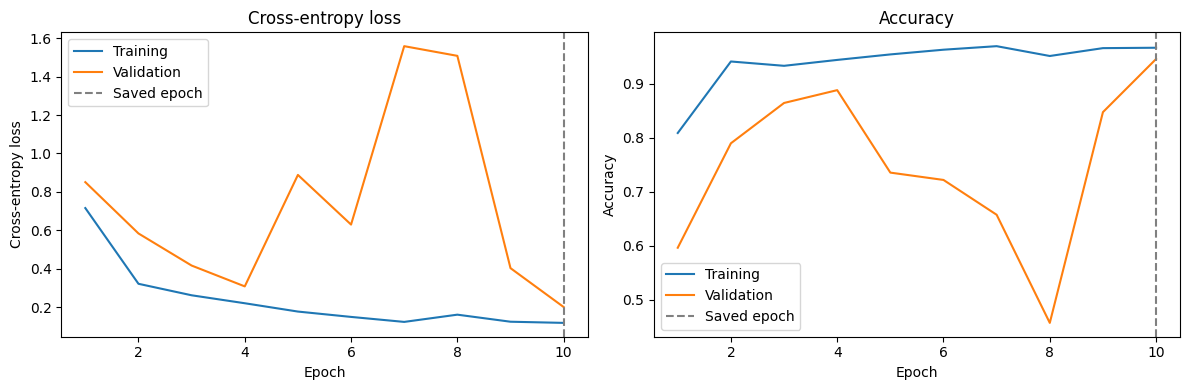

Weights file size: 0.39 MB


In [4]:
model.load_state_dict(torch.load(weights_path, map_location=device, weights_only=True))
 
test_loss, test_acc, actual, predicted = run_epoch(
    test_loader, collect_predictions=True
)
class_ids = list(range(len(class_names)))
 
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.2%}")
print(classification_report(
    actual, predicted, labels=class_ids,
    target_names=class_names, digits=4, zero_division=0,
))
 
_, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    actual, predicted, labels=class_ids, display_labels=class_names,
    xticks_rotation=35, cmap="Blues", ax=ax,
)
ax.set_title("Test-set confusion matrix")
plt.tight_layout()
plt.show()
 
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
 
for ax, metric, title in zip(axes, ["loss", "acc"], ["Cross-entropy loss", "Accuracy"]):
    ax.plot(epochs, history[f"train_{metric}"], label="Training")
    ax.plot(epochs, history[f"val_{metric}"], label="Validation")
    ax.axvline(best_epoch, linestyle="--", color="gray", label="Saved epoch")
    ax.set(xlabel="Epoch", ylabel=title, title=title)
    ax.legend()
 
plt.tight_layout()
plt.show()
 
print(f"Weights file size: {weights_path.stat().st_size / 1_000_000:.2f} MB")